In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import random
from tensorflow.keras import layers,models
from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

In [2]:
train_path=r"C:\Users\hp\Downloads\archive (5)\train"
test_path=r"C:\Users\hp\Downloads\archive (5)\test"

In [3]:
IMG_SIZE=(224,224)
BATCH_SIZE=32
SEED=42

In [4]:
train_dataset=image_dataset_from_directory(
    train_path,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.20,
    subset="training",
    seed=SEED
)

validation_dataset=image_dataset_from_directory(
    train_path,image_size=IMG_SIZE,batch_size=BATCH_SIZE,
    validation_split=0.20,subset="validation",seed=SEED
)

test_dataset=image_dataset_from_directory(
    test_path,image_size=IMG_SIZE,batch_size=BATCH_SIZE,
    shuffle=False
)

Found 2670 files belonging to 28 classes.
Using 2136 files for training.
Found 2670 files belonging to 28 classes.
Using 534 files for validation.
Found 252 files belonging to 27 classes.


In [5]:
class_names=train_dataset.class_names
print("Number of classes:",len(class_names))
print("\nDisease classes")

for i, name in enumerate(class_names):
    print(i, ":", name)

Number of classes: 28

Disease classes
0 : Apple_Scab_Leaf
1 : Apple_leaf
2 : Apple_rust_leaf
3 : Bell_pepper_leaf
4 : Bell_pepper_leaf_spot
5 : Blueberry_leaf
6 : Cherry_leaf
7 : Corn_Gray_leaf_spot
8 : Corn_leaf_blight
9 : Corn_rust_leaf
10 : Peach_leaf
11 : Potato_leaf_early_blight
12 : Potato_leaf_late_blight
13 : Raspberry_leaf
14 : Soyabean_leaf
15 : Squash_Powdery_mildew_leaf
16 : Strawberry_leaf
17 : Tomato_Early_blight_leaf
18 : Tomato_Septoria_leaf_spot
19 : Tomato_leaf
20 : Tomato_leaf_bacterial_spot
21 : Tomato_leaf_late_blight
22 : Tomato_leaf_mosaic_virus
23 : Tomato_leaf_yellow_virus
24 : Tomato_mold_leaf
25 : Tomato_two_spotted_spider_mites_leaf
26 : grape_leaf
27 : grape_leaf_black_rot


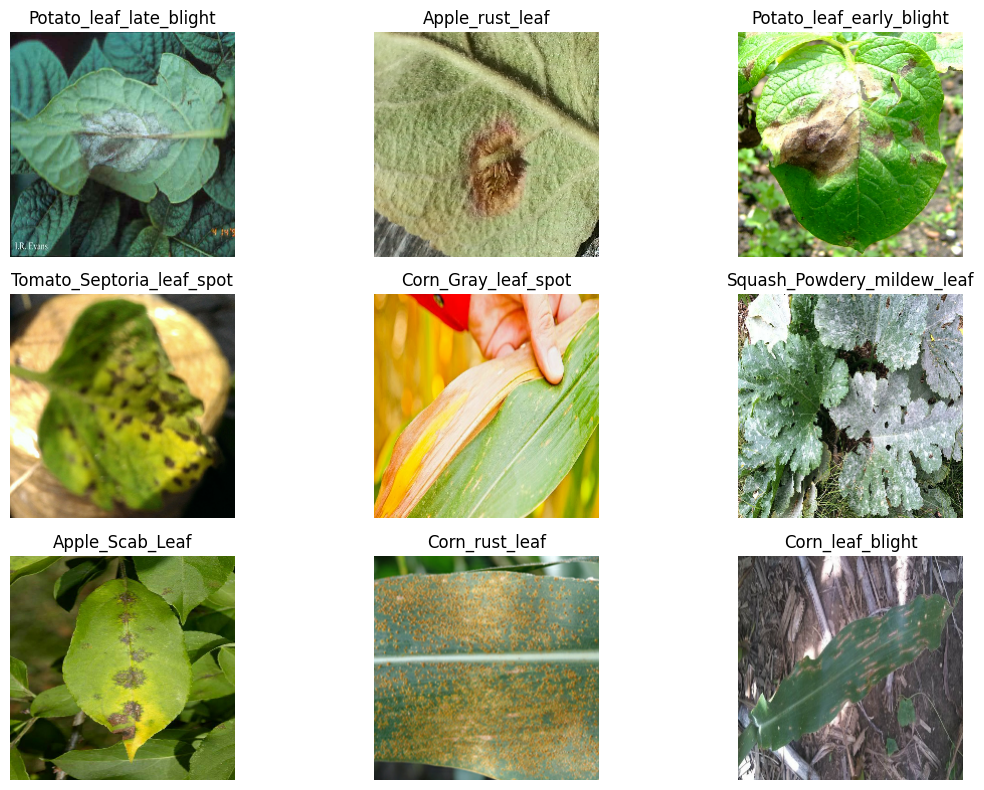

In [6]:
plt.figure(figsize=(12,8))
for images,labels in train_dataset.take(1):
    for i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
AUTOTUNE=tf.data.AUTOTUNE
train_dataset=train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset=validation_dataset.prefetch(buffer_size=AUTOTUNE)
test_dataset=test_dataset.prefetch(buffer_size=AUTOTUNE)

In [8]:
data_augmentation=tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

In [9]:
base_model=MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224,224,3)
)
base_model.trainable=False

In [10]:
model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    data_augmentation,
    layers.Rescaling(1./127.5, offset=-1),   # same as MobileNetV2 preprocess_input
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax")
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ sequential (Sequential)              │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ rescaling (Rescaling)                │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1280)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 28)                  │          35,868 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,293,852 (8.75 MB)

 Trainable params: 35,868 (140.11 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [12]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5,
    callbacks=callbacks 
)

Epoch 1/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 84s 1s/step - accuracy: 0.2097 - loss: 2.8543 - val_accuracy: 0.3483 - val_loss: 2.1380 - learning_rate: 0.0010
Epoch 2/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.4190 - loss: 1.9427 - val_accuracy: 0.4270 - val_loss: 1.8175 - learning_rate: 0.0010
Epoch 3/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.4967 - loss: 1.6392 - val_accuracy: 0.4906 - val_loss: 1.6332 - learning_rate: 0.0010
Epoch 4/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 83s 1s/step - accuracy: 0.5520 - loss: 1.4377 - val_accuracy: 0.5150 - val_loss: 1.5190 - learning_rate: 0.0010
Epoch 5/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 75s 1s/step - accuracy: 0.5875 - loss: 1.3497 - val_accuracy: 0.5356 - val_loss: 1.4945 - learning_rate: 0.0010


In [13]:
base_model.trainable=True
for layer in base_model.layers[:-30]:
    layer.trainable= False

In [14]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),  
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_fine = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5,
    callbacks=callbacks
)

Epoch 1/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 104s 1s/step - accuracy: 0.4209 - loss: 1.9848 - val_accuracy: 0.5524 - val_loss: 1.4764 - learning_rate: 1.0000e-05
Epoch 2/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 91s 1s/step - accuracy: 0.4902 - loss: 1.7330 - val_accuracy: 0.5468 - val_loss: 1.4733 - learning_rate: 1.0000e-05
Epoch 3/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 105s 2s/step - accuracy: 0.5389 - loss: 1.5448 - val_accuracy: 0.5543 - val_loss: 1.4677 - learning_rate: 1.0000e-05
Epoch 4/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 114s 2s/step - accuracy: 0.5613 - loss: 1.4740 - val_accuracy: 0.5562 - val_loss: 1.4492 - learning_rate: 1.0000e-05
Epoch 5/5
67/67 ━━━━━━━━━━━━━━━━━━━━ 139s 2s/step - accuracy: 0.5997 - loss: 1.3727 - val_accuracy: 0.5655 - val_loss: 1.4320 - learning_rate: 1.0000e-05


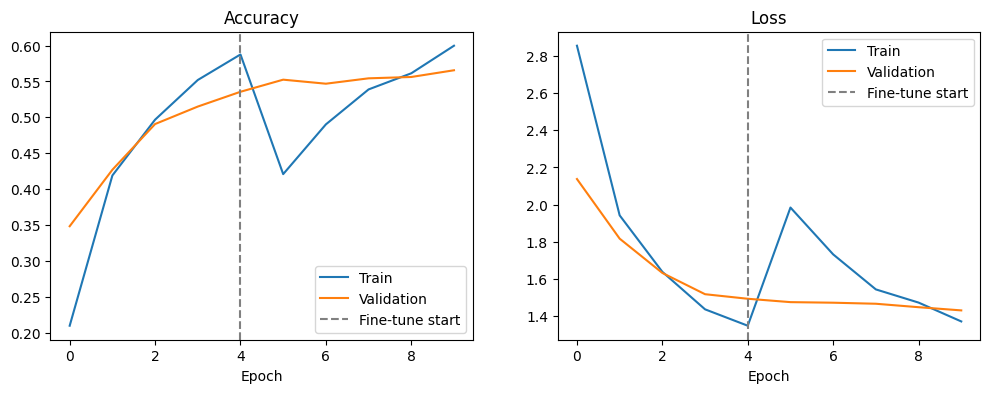

In [15]:
acc     = history.history["accuracy"] + history_fine.history["accuracy"]
val_acc = history.history["val_accuracy"] + history_fine.history["val_accuracy"]
loss     = history.history["loss"]     + history_fine.history["loss"]
val_loss = history.history["val_loss"] + history_fine.history["val_loss"]
split = len(history.history["accuracy"]) - 1

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(acc, label="Train"); plt.plot(val_acc, label="Validation")
plt.axvline(split, color="gray", linestyle="--", label="Fine-tune start")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(loss, label="Train"); plt.plot(val_loss, label="Validation")
plt.axvline(split, color="gray", linestyle="--", label="Fine-tune start")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()
plt.show()

In [16]:
test_loss, test_acc = model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:.4f}")

8/8 ━━━━━━━━━━━━━━━━━━━━ 9s 907ms/step - accuracy: 0.4365 - loss: 2.1306
Test accuracy: 0.4365


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


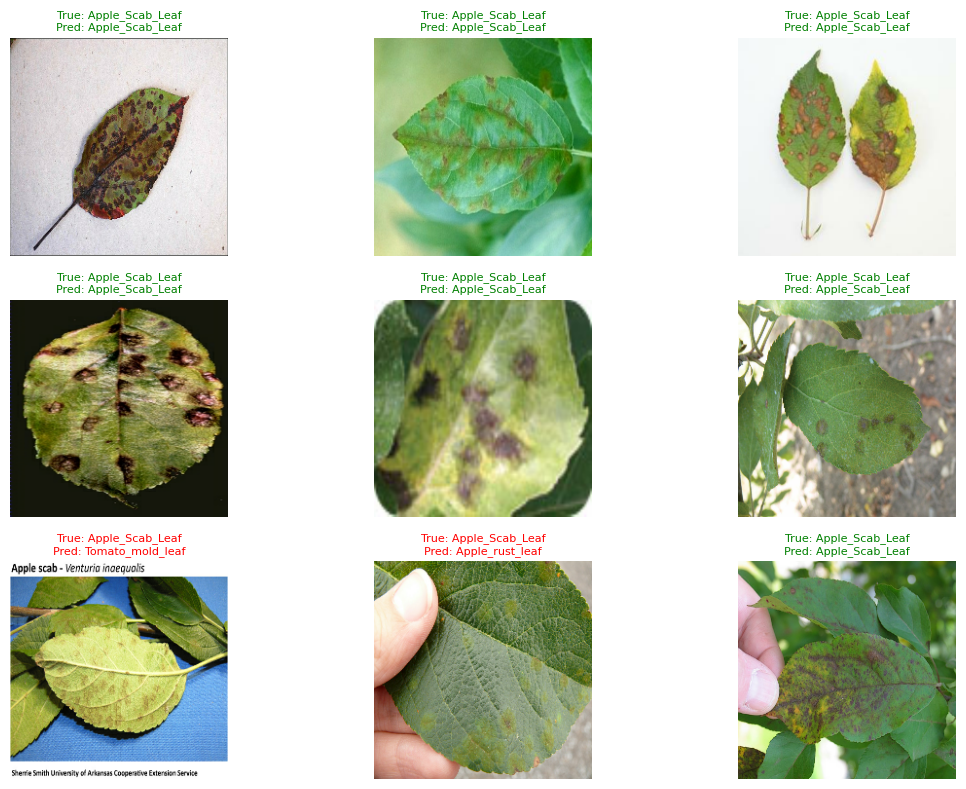

In [17]:
plt.figure(figsize=(12, 8))
for images, labels in test_dataset.take(1):
    preds = np.argmax(model.predict(images), axis=1)
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        color = "green" if preds[i] == labels[i] else "red"
        plt.title(f"True: {class_names[labels[i]]}\nPred: {class_names[preds[i]]}", color=color, fontsize=8)
        plt.axis("off")
plt.tight_layout()
plt.show()

In [18]:
model.save("mobilenet_leaf_disease.keras")